# Análise exploratória do risco de atraso

## Contexto do problema

Queremos investigar quais informações disponíveis até a aprovação do pagamento estão associadas à entrega após a data prometida. A análise pode orientar uma etapa futura de estimativa do risco e ajudar a priorizar ações operacionais.

O escopo é deliberadamente específico: o notebook explora hipóteses sobre os pedidos da Olist, em vez de descrever todo o conjunto de dados. As associações encontradas são indícios exploratórios, não evidência de causalidade.

## Etapas da análise

O fluxo parte da definição do instante em que a previsão seria feita e segue até a comparação de grupos de pedidos:

1. Fixar a aprovação do pagamento como referência da previsão e evitar vazamento de informação futura.
2. Ler os arquivos de pedidos, itens e clientes e conferir suas dimensões.
3. Criar o indicador de atraso e resumir a tabela de itens para manter um registro por pedido.
4. Integrar as informações e criar variáveis que poderiam estar disponíveis na previsão.
5. Explorar oito perguntas e registrar o que os dados sugerem, junto com as limitações.

A pergunta que orienta o trabalho é: **o que sabemos no momento da aprovação que pode ajudar a distinguir pedidos com maior risco de atraso?**

In [29]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid", palette="Blues_r")

# Procura a raiz do projeto a partir do diretório de execução do notebook.
ROOT = next(
    (
        candidate
        for base in (Path.cwd(), *Path.cwd().parents)
        for candidate in (base, base / "Olist_PH")
        if (candidate / "pyproject.toml").is_file()
        and (candidate / "module_olist").is_dir()
    ),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Não foi possível localizar a raiz do projeto Olist.")

DATA_DIR = ROOT / "data"
DATA_DIR

WindowsPath('c:/Users/phfon/OneDrive/Documentos/GitHub/MachineLearningCimatecProjetos/Olist_PH/data')

## 1. Definição do momento de previsão e prevenção de vazamento

Para esta análise, imaginamos que a estimativa seria produzida assim que o pagamento fosse aprovado (order_approved_at). Portanto, uma variável explicativa precisa existir ou ser conhecida até esse instante.

| Pode ser considerado na previsão | Surge depois da previsão e não deve ser feature |
|---|---|
| Compra, aprovação e prazo estimado | Envio efetivo à transportadora |
| Identificador e localização do cliente | Data em que o pedido chegou ao cliente |
| Itens, vendedores, valores e frete informados no pedido | Avaliação e comentário publicados após a compra |

A data de entrega realizada será usada somente para construir o rótulo histórico (is_late). Incluí-la entre as entradas do modelo revelaria diretamente o resultado que se deseja prever.

## 2. Leitura das fontes

Usaremos três arquivos do conjunto Olist: pedidos, itens e clientes. Eles têm granularidades diferentes; por isso, a tabela de itens será resumida antes de ser associada aos pedidos.

In [16]:
FILES = {
    "orders": "olist_orders_dataset.csv",
    "items": "olist_order_items_dataset.csv",
    "customers": "olist_customers_dataset.csv",
}
DATE_COLUMNS = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]
RAW_DIR = DATA_DIR / "raw"

orders = pd.read_csv(
    RAW_DIR / FILES["orders"],
    parse_dates=DATE_COLUMNS,
)
items = pd.read_csv(RAW_DIR / FILES["items"])
customers = pd.read_csv(RAW_DIR / FILES["customers"])

for label, table in (("Pedidos", orders), ("Itens", items), ("Clientes", customers)):
    print(f"{label}: {table.shape}")

Pedidos: (99441, 8)
Itens: (112650, 7)
Clientes: (99441, 5)


## 3. Definição do rótulo

Para comparar prazo e realização, restringimos o histórico a pedidos entregues com as datas necessárias preenchidas. Registros que ainda não chegaram ao cliente não permitem saber se a promessa foi cumprida.

O rótulo vale 1 quando a data de entrega ao cliente é posterior à data estimada; em caso contrário, vale 0. A data real entra apenas nesta classificação histórica, não nas variáveis que descrevem o pedido no instante da previsão.

In [17]:
# Usamos somente pedidos entregues com as datas necessárias para comparar
# o prazo prometido ao resultado observado e situar o instante da previsão.
required_dates = [
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
    "order_approved_at",
]
delivered_orders = orders.loc[
    orders["order_status"].eq("delivered")
    & orders[required_dates].notna().all(axis=1)
].copy()

# A classe positiva identifica entrega posterior à data estimada.
delivered_orders["is_late"] = (
    delivered_orders["order_delivered_customer_date"]
    > delivered_orders["order_estimated_delivery_date"]
).astype("int8")

print(f"Total na tabela original: {len(orders):,}")
print(f"Pedidos incluídos na análise: {len(delivered_orders):,}")
display(delivered_orders["is_late"].value_counts(dropna=False))

Total na tabela original: 99,441
Pedidos incluídos na análise: 96,456


is_late
0    88630
1     7826
Name: count, dtype: int64

## 4. Preparação da tabela analítica

A tabela de itens pode conter várias linhas para o mesmo pedido. Se a juntarmos diretamente com pedidos, um pedido com muitos itens seria replicado e passaria a influenciar mais os cálculos. Primeiro vamos resumir os itens e, depois, unir as tabelas mantendo a unidade de análise em um pedido.

### 4.1 Resumo dos itens por pedido

In [18]:
# Resumo da tabela de itens: uma linha agregada para cada pedido.
items_agg = (
    items.groupby("order_id", as_index=False)
    .agg(
        item_count=("order_item_id", "count"),
        seller_count=("seller_id", "nunique"),
        total_price=("price", "sum"),
        total_freight=("freight_value", "sum"),
    )
)

assert items_agg["order_id"].is_unique, "A agregação deve deixar um registro por pedido."
display(items_agg.head())

,order_id,item_count,seller_count,total_price,total_freight
0,00010242fe8c5a6d1ba2dd792cb16214,1,1,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,1,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,1,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,1,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,1,199.90,18.14


### 4.2 Junção com pedidos e clientes

In [19]:
# Enriquecemos cada pedido com o resumo dos itens e a localização do cliente.
orders_analysis = (
    delivered_orders
    .merge(
        items_agg,
        on="order_id",
        how="left",
        validate="one_to_one",
    )
    .merge(
        customers[["customer_id", "customer_state", "customer_city"]],
        on="customer_id",
        how="left",
        validate="many_to_one",
    )
)

assert orders_analysis["order_id"].is_unique, "A tabela final deve ter pedidos únicos."
assert len(orders_analysis) == len(delivered_orders), "A junção alterou a quantidade de pedidos."

print(f"Dimensões da tabela analítica: {orders_analysis.shape}")
display(orders_analysis.head())

Dimensões da tabela analítica: (96456, 15)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,is_late,item_count,seller_count,total_price,total_freight,customer_state,customer_city
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,0,1,1,29.99,8.72,SP,sao paulo
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,0,1,1,118.70,22.76,BA,barreiras
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,0,1,1,159.90,19.22,GO,vianopolis
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,0,1,1,45.00,27.20,RN,sao goncalo do amarante
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,0,1,1,19.90,8.72,SP,santo andre


## 5. Variáveis derivadas

Vamos criar algumas medidas de calendário e do prazo prometido que podem ser calculadas com informações conhecidas no instante definido. Antes de usá-las em um modelo, ainda será necessário avaliar sua utilidade e conferir novamente se não dependem de eventos posteriores.

In [20]:
# Variáveis de calendário e de tempo prometido, calculadas sem usar a data
# de entrega efetiva como entrada.
orders_analysis["promised_days"] = (
    orders_analysis["order_estimated_delivery_date"]
    - orders_analysis["order_approved_at"]
).dt.total_seconds() / 86_400

purchase_time = orders_analysis["order_purchase_timestamp"]
orders_analysis["purchase_month"] = purchase_time.dt.month
orders_analysis["purchase_weekday"] = purchase_time.dt.dayofweek
orders_analysis["purchase_hour"] = purchase_time.dt.hour

display(orders_analysis["promised_days"].describe().to_frame().T)
print("Prazos prometidos não positivos:", orders_analysis["promised_days"].le(0).sum())

,count,mean,std,min,25%,50%,75%,max
promised_days,96456.0,23.306482,8.765103,-6.664225,17.905885,22.668762,28.066727,153.57603


Prazos prometidos não positivos: 6


# Pergunta 1 — Qual parcela dos pedidos entregues atrasou?

**Hipótese:** os atrasos representam uma fração menor dos pedidos, então as duas classes podem ficar desbalanceadas.

**Por que medir isso:** uma acurácia alta pode ser enganosa se um modelo simplesmente sempre prever a classe mais comum. Primeiro examinamos a proporção de cada classe; depois poderemos escolher métricas mais apropriadas.

Proporção de pedidos atrasados: 8.11%


,proporcao
is_late,
0,0.918865
1,0.081135


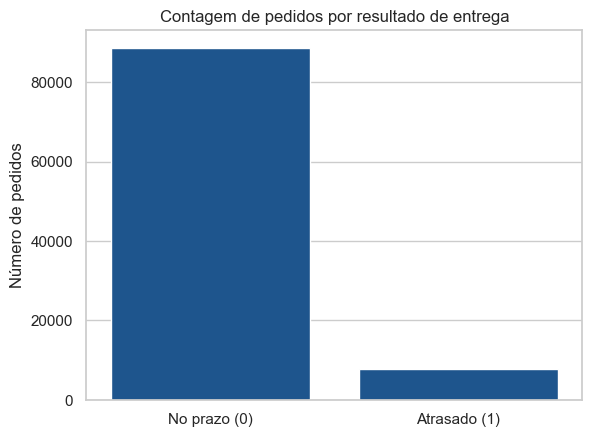

In [21]:
late_rate = orders_analysis["is_late"].mean()
print(f"Proporção de pedidos atrasados: {late_rate:.2%}")

class_share = (
    orders_analysis["is_late"]
    .value_counts(normalize=True)
    .rename("proporcao")
    .to_frame()
)
display(class_share)

ax = sns.countplot(data=orders_analysis, x="is_late", order=[0, 1])
ax.set_xticks([0, 1], labels=["No prazo (0)", "Atrasado (1)"])
ax.set_title("Contagem de pedidos por resultado de entrega")
ax.set_xlabel("")
ax.set_ylabel("Número de pedidos")
plt.show()

**Leitura dos resultados — pergunta 1**

- No recorte analisado, 7.826 de 96.456 pedidos entregues ficaram atrasados, cerca de 8,1%.
- Isso confirma um desbalanceamento: a maioria foi entregue no prazo.
- Um classificador que sempre previsse “no prazo” teria aproximadamente 91,9% de acurácia, mas não identificaria nenhum atraso. Para uma modelagem futura, será importante observar recall e precisão da classe atrasada, F1 e AUC, além da acurácia.

Esses valores descrevem o recorte carregado; devem ser recalculados se os arquivos de entrada mudarem.

# Pergunta 2 — O prazo prometido distingue pedidos atrasados?

**Hipótese:** quando o prazo entre aprovação e entrega prevista é muito curto, há menos margem para absorver imprevistos logísticos.

Vamos comparar a proporção de atrasos em intervalos de prazo. A quantidade de pedidos em cada intervalo também importa: percentuais de grupos pequenos tendem a oscilar mais.

,taxa_atraso,n_pedidos
promised_days_bin,,
0-7,0.283445,1637
8-14,0.067644,11531
15-21,0.090729,25185
22-28,0.085197,33757
29+,0.058275,24333


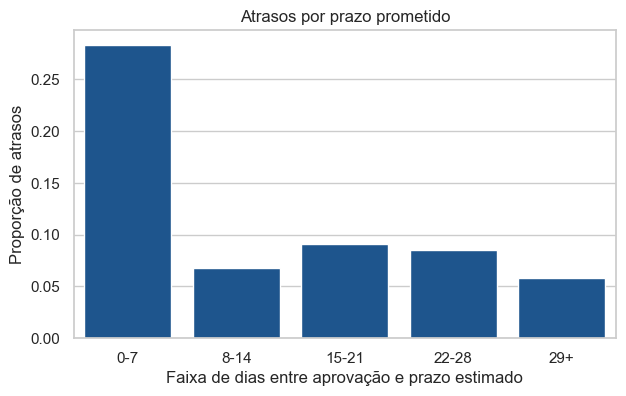

In [22]:
# Agrupamos o prazo estimado para comparar proporções de atraso.
orders_analysis["promised_days_bin"] = pd.cut(
    orders_analysis["promised_days"],
    bins=[0, 7, 14, 21, 28, 100],
    labels=["0-7", "8-14", "15-21", "22-28", "29+"],
)

q2 = (
    orders_analysis.groupby("promised_days_bin", observed=True)["is_late"]
    .agg(taxa_atraso="mean", n_pedidos="size")
)
display(q2)

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=q2.reset_index(), x="promised_days_bin", y="taxa_atraso", ax=ax)
ax.set_xlabel("Faixa de dias entre aprovação e prazo estimado")
ax.set_ylabel("Proporção de atrasos")
ax.set_title("Atrasos por prazo prometido")
plt.show()

**Leitura dos resultados — pergunta 2**

- No resultado desta execução, a faixa de 0 a 7 dias teve atraso em aproximadamente 28,3% dos pedidos, acima das demais faixas (cerca de 5,8% a 9,1%).
- Essa faixa reúne cerca de 1.637 pedidos, aproximadamente 1,7% do recorte; o tamanho reduzido recomenda cautela ao generalizar.
- A partir de oito dias, não aparece uma queda contínua da taxa conforme o prazo aumenta. A associação linear isolada também é fraca (correlação aproximada de -0,06).

A hipótese encontra apoio para prazos excepcionalmente curtos, mas o número de dias prometidos não explica sozinho o atraso.

# Pergunta 3 — O tamanho e a composição do pedido se relacionam com atrasos?

**Hipótese:** mais itens ou mais vendedores podem aumentar a coordenação necessária para completar um pedido.

A comparação separa quantidade de itens e presença de múltiplos vendedores. Os grupos de maior tamanho podem ter poucas observações, então suas taxas devem ser lidas junto com as contagens.

,taxa_atraso,n_pedidos
item_count,,
1,0.082894,86822
2,0.066297,7391
3,0.062021,1306
4,0.056566,495
5,0.067358,193
6,0.083770,191
7,0.000000,22
8,0.000000,8
9,0.000000,3


,taxa_atraso,n_pedidos
multi_seller,,
False,0.082033,95181
True,0.014118,1275


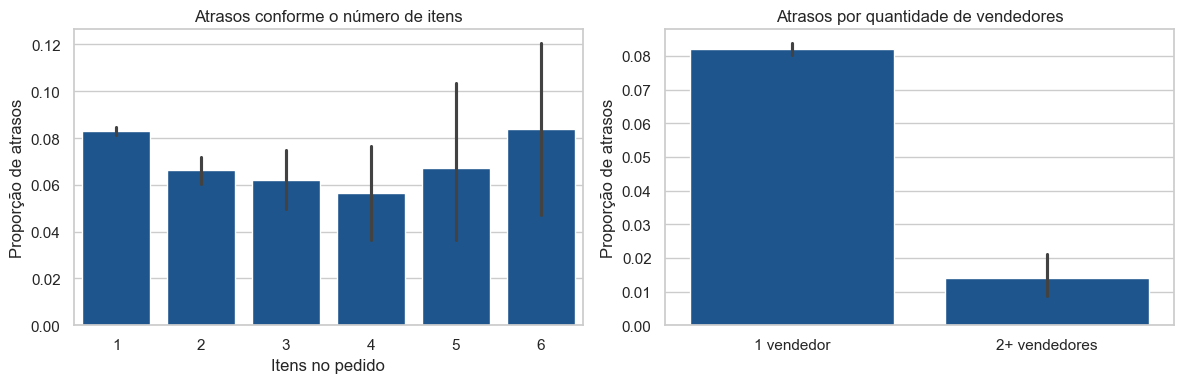

In [23]:
q3_items = (
    orders_analysis.groupby("item_count")["is_late"]
    .agg(taxa_atraso="mean", n_pedidos="size")
)
display(q3_items)

# Comparamos pedidos de um vendedor com os que envolvem vários vendedores.
orders_analysis["multi_seller"] = orders_analysis["seller_count"].gt(1)
q3_sellers = (
    orders_analysis.groupby("multi_seller")["is_late"]
    .agg(taxa_atraso="mean", n_pedidos="size")
)
display(q3_sellers)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(
    data=orders_analysis.loc[orders_analysis["item_count"].le(6)],
    x="item_count",
    y="is_late",
    ax=axes[0],
)
axes[0].set_title("Atrasos conforme o número de itens")
axes[0].set_xlabel("Itens no pedido")
axes[0].set_ylabel("Proporção de atrasos")

sns.barplot(data=orders_analysis, x="multi_seller", y="is_late", ax=axes[1])
axes[1].set_xticks([0, 1], labels=["1 vendedor", "2+ vendedores"])
axes[1].set_title("Atrasos por quantidade de vendedores")
axes[1].set_xlabel("")
axes[1].set_ylabel("Proporção de atrasos")

plt.tight_layout()
plt.show()

**Leitura dos resultados — pergunta 3**

- Até seis itens, a taxa não cresce de forma regular; pedidos com mais itens são raros, então estimativas de grupos extremos são menos estáveis.
- No resultado desta execução, pedidos com mais de um vendedor tiveram taxa menor (aproximadamente 1,4%) do que os pedidos com um vendedor (cerca de 8,2%), ao contrário da hipótese inicial.
- A diferença merece investigação, não uma explicação causal. Pedidos com múltiplos vendedores representam uma parcela pequena da amostra e podem diferir em outras características.

Assim, a quantidade de itens não mostra um padrão claro nesta exploração. A variável de múltiplos vendedores pode ser informativa, mas precisa de análise adicional antes de ser adotada.

# Pergunta 4 — A taxa de atraso varia entre estados dos clientes?

**Hipótese:** distância e diferenças de infraestrutura logística podem se refletir em taxas distintas entre regiões.

Para reduzir o ruído de grupos com poucos pedidos, a visualização considera estados com pelo menos 100 observações. Isso não elimina incerteza; apenas aplica um filtro mínimo de volume.

,taxa_atraso,n_pedidos
customer_state,,
AL,0.239295,397
MA,0.196927,716
PI,0.159664,476
CE,0.153365,1278
SE,0.152239,335
BA,0.140356,3256
RJ,0.134759,12348
TO,0.127737,274
PA,0.123679,946


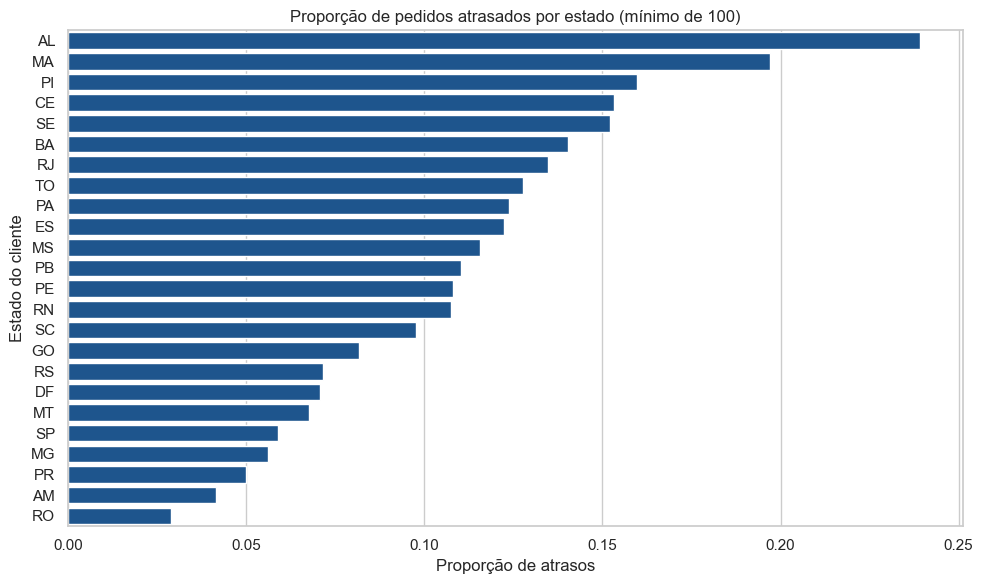

In [24]:
# Excluímos estados com menos de 100 pedidos para evitar destacar taxas
# calculadas com grupos muito pequenos.
state_counts = orders_analysis["customer_state"].value_counts()
valid_states = state_counts.index[state_counts.ge(100)]

q4 = (
    orders_analysis.loc[orders_analysis["customer_state"].isin(valid_states)]
    .groupby("customer_state")["is_late"]
    .agg(taxa_atraso="mean", n_pedidos="size")
    .sort_values("taxa_atraso", ascending=False)
)
display(q4)

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=q4.reset_index(), y="customer_state", x="taxa_atraso", ax=ax)
ax.set_xlabel("Proporção de atrasos")
ax.set_ylabel("Estado do cliente")
ax.set_title("Proporção de pedidos atrasados por estado (mínimo de 100)")
plt.tight_layout()
plt.show()

**Leitura dos resultados — pergunta 4**

- Nesta execução, alguns estados do Norte e Nordeste tiveram taxas acima da média do recorte, enquanto estados do Sul e Sudeste apareceram entre os menores valores.
- O padrão é compatível com a hipótese geográfica, mas não prova que o estado seja a causa: a variável pode representar distância, localização de centros de distribuição ou outros fatores não observados.
- Um estado abrange localidades diversas. Para uma análise futura, distâncias e tempos de transporte mais diretos podem representar melhor o contexto logístico.

A localização do cliente parece merecer investigação como possível feature, com validação em períodos e amostras diferentes.

# Pergunta 5 — Existem diferenças de atraso por mês da compra?

**Hipótese:** períodos de pico ou de mudança no volume operacional podem coincidir com maior proporção de atrasos.

Vamos observar a taxa e a quantidade de pedidos por mês em painéis separados. Assim, um percentual alto não será interpretado sem considerar o volume de observações.

,taxa_atraso,n_pedidos
purchase_month,,
1,0.062300,7817
2,0.134334,8196
3,0.171536,9549
4,0.059554,9101
5,0.066446,10294
6,0.022099,9231
7,0.040786,10028
8,0.075778,10544
9,0.052277,4151


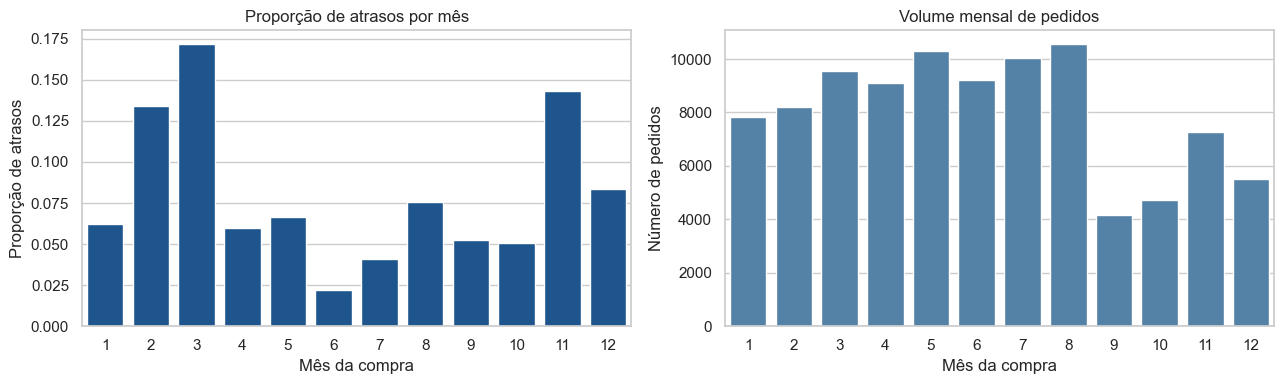

In [25]:
q5 = (
    orders_analysis.groupby("purchase_month")["is_late"]
    .agg(taxa_atraso="mean", n_pedidos="size")
)
display(q5)

# Mostramos proporção e volume separadamente para contextualizar cada mês.
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharex=True)
month_data = q5.reset_index()

sns.barplot(data=month_data, x="purchase_month", y="taxa_atraso", ax=axes[0])
axes[0].set_title("Proporção de atrasos por mês")
axes[0].set_xlabel("Mês da compra")
axes[0].set_ylabel("Proporção de atrasos")

sns.barplot(data=month_data, x="purchase_month", y="n_pedidos", color="steelblue", ax=axes[1])
axes[1].set_title("Volume mensal de pedidos")
axes[1].set_xlabel("Mês da compra")
axes[1].set_ylabel("Número de pedidos")

plt.tight_layout()
plt.show()

**Leitura dos resultados — pergunta 5**

- No recorte atual, março, novembro e fevereiro aparecem entre os meses com taxas maiores; junho e julho, entre os menores.
- Novembro também tem volume elevado, o que é compatível com uma possível pressão sazonal, mas os gráficos não identificam sua causa.
- Como a base cobre um intervalo limitado, não é seguro concluir que esse padrão se repete a cada ano. Seria útil comparar anos e investigar eventos e capacidade logística separadamente.

Os resultados sugerem uma possível variação temporal, ainda a confirmar com dados de vários períodos.

# Pergunta 6 — O dia da semana da compra está associado ao atraso?

**Hipótese:** pedidos feitos no fim de semana poderiam ter outro comportamento por causa de calendários de operação de lojas, armazéns e transportadoras.

Comparamos as taxas por dia e também agrupamos sábado e domingo em uma categoria de fim de semana.

,taxa_atraso,n_pedidos
purchase_weekday,,
0,0.090504,15701
1,0.084892,15502
2,0.078015,15074
3,0.075698,14320
4,0.084497,13681
5,0.076041,10547
6,0.074886,11631


,taxa_atraso,n_pedidos
is_weekend,,
False,0.082837,74278
True,0.075435,22178


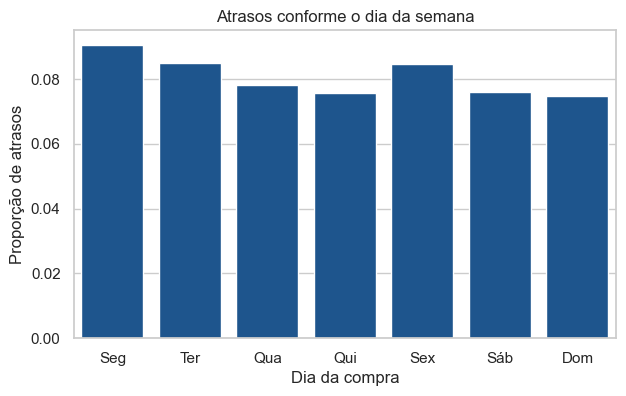

In [26]:
q6_weekday = (
    orders_analysis.groupby("purchase_weekday")["is_late"]
    .agg(taxa_atraso="mean", n_pedidos="size")
)
display(q6_weekday)

orders_analysis["is_weekend"] = orders_analysis["purchase_weekday"].isin([5, 6])
q6_weekend = (
    orders_analysis.groupby("is_weekend")["is_late"]
    .agg(taxa_atraso="mean", n_pedidos="size")
)
display(q6_weekend)

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=q6_weekday.reset_index(), x="purchase_weekday", y="taxa_atraso", ax=ax)
ax.set_xticks(range(7), labels=["Seg", "Ter", "Qua", "Qui", "Sex", "Sáb", "Dom"])
ax.set_xlabel("Dia da compra")
ax.set_ylabel("Proporção de atrasos")
ax.set_title("Atrasos conforme o dia da semana")
plt.show()

**Leitura dos resultados — pergunta 6**

- As taxas observadas por dia ficaram próximas, variando aproximadamente de 7,5% a 9,1%.
- No agrupamento desta execução, o fim de semana apresentou proporção ligeiramente menor que os dias úteis, e não maior como sugeria a hipótese.

A diferença visual é pequena e, sem intervalos de incerteza ou controle por outras variáveis, não sustenta uma conclusão forte. O dia da semana isolado não parece prioridade para esta etapa exploratória.

# Pergunta 7 — O horário da compra ajuda a distinguir atrasos?

**Hipótese:** compras realizadas de madrugada poderiam seguir um fluxo de aprovação diferente e, por isso, afetar o prazo disponível para a logística.

Para facilitar a comparação, agrupamos as horas em quatro períodos do dia. Os limites são convenções desta análise, não categorias fornecidas pela fonte.

,taxa_atraso,n_pedidos
purchase_turno,,
madrugada,0.082081,4593
manhã,0.075584,21592
tarde,0.080928,37169
noite,0.084859,33102


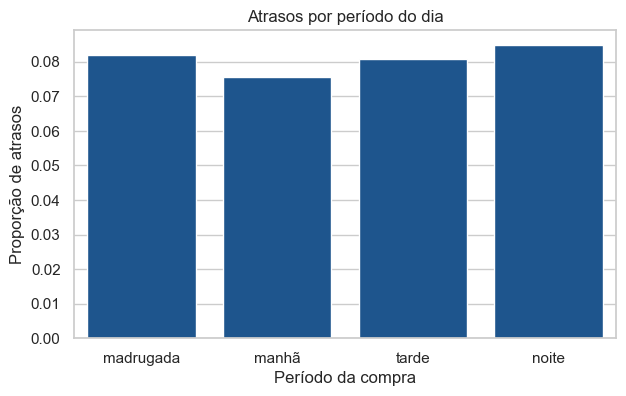

In [27]:
def turno_do_dia(hour: int) -> str:
    """Classifica a hora da compra em um período do dia."""
    if 0 <= hour < 6:
        return "madrugada"
    if 6 <= hour < 12:
        return "manhã"
    if 12 <= hour < 18:
        return "tarde"
    return "noite"

orders_analysis["purchase_turno"] = orders_analysis["purchase_hour"].apply(turno_do_dia)
turn_order = ["madrugada", "manhã", "tarde", "noite"]
q7 = (
    orders_analysis.groupby("purchase_turno")["is_late"]
    .agg(taxa_atraso="mean", n_pedidos="size")
    .reindex(turn_order)
)
display(q7)

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=q7.reset_index(), x="purchase_turno", y="taxa_atraso", order=turn_order, ax=ax)
ax.set_xlabel("Período da compra")
ax.set_ylabel("Proporção de atrasos")
ax.set_title("Atrasos por período do dia")
plt.show()

**Leitura dos resultados — pergunta 7**

- As taxas calculadas ficaram próximas entre os períodos: aproximadamente 7,6% a 8,5% nesta execução.
- A madrugada não apresentou o maior valor, portanto os resultados não apoiam a hipótese inicial.

Essa diferença pequena, avaliada sem controles adicionais, não indica que horário ou turno devam ser priorizados como preditores.

# Pergunta 8 — A proporção do frete em relação aos itens acompanha o atraso?

**Hipótese:** uma participação alta do frete no total dos produtos poderia refletir distâncias ou condições logísticas associadas a maior risco.

Calculamos a razão entre frete total e valor dos itens, comparamos quartis e observamos a correlação linear. A razão é apenas um indicador indireto; não equivale a uma medida de distância ou duração de transporte.

,count,mean,std,min,25%,50%,75%,max
freight_ratio,96456.0,0.308395,0.311637,0.0,0.132017,0.224374,0.380585,21.447059


,taxa_atraso,n_pedidos
freight_ratio_q,,
Q1 (mais barato),0.082850,24116
Q2,0.077567,24134
Q3,0.081009,24096
Q4 (mais caro),0.083119,24110


Correlação entre frete relativo e atraso: 0.007


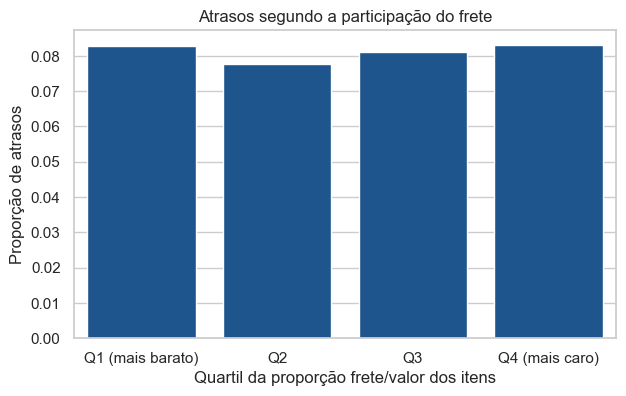

In [28]:
orders_analysis["freight_ratio"] = (
    orders_analysis["total_freight"] / orders_analysis["total_price"]
)
display(orders_analysis["freight_ratio"].describe().to_frame().T)

orders_analysis["freight_ratio_q"] = pd.qcut(
    orders_analysis["freight_ratio"],
    q=4,
    labels=["Q1 (mais barato)", "Q2", "Q3", "Q4 (mais caro)"],
)
q8 = (
    orders_analysis.groupby("freight_ratio_q", observed=True)["is_late"]
    .agg(taxa_atraso="mean", n_pedidos="size")
)
display(q8)

correlation = orders_analysis["freight_ratio"].corr(orders_analysis["is_late"])
print(f"Correlação entre frete relativo e atraso: {correlation:.3f}")

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=q8.reset_index(), x="freight_ratio_q", y="taxa_atraso", ax=ax)
ax.set_xlabel("Quartil da proporção frete/valor dos itens")
ax.set_ylabel("Proporção de atrasos")
ax.set_title("Atrasos segundo a participação do frete")
plt.show()

**Leitura dos resultados — pergunta 8**

- Os quartis de frete relativo apresentaram taxas próximas, aproximadamente entre 7,8% e 8,3% nesta execução.
- A correlação linear com o indicador de atraso foi quase nula (cerca de 0,007).
- A hipótese não encontra apoio claro nesse resumo. O custo relativo pode não representar tempo de trânsito e não revela, sozinho, a complexidade logística.

Os resultados são descritivos; uma conclusão de modelagem exigiria validação em dados separados, análise conjunta com outras variáveis e revisão de possíveis vieses.